<a href="https://colab.research.google.com/github/Andre-Victor-Vasconcelos/Redes-Neurais-Artificiais---Francisco-de-Assis-Boldt/blob/main/Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Base "Airline Passengers"

**Base Escolhida:** Airline Passengers (Total mensal de passageiros de companhias aéreas americanas de 1949 a 1960). Escolhida por possuir forte sazonalidade anual e tendência de alta, sendo ideal para validar redes neurais.

**Justificativa dos parâmetros:** O tamanho da janela (window_size = 12) foi escolhido por representar exatamente o ciclo de 1 ano (12 meses), dando o contexto perfeito para a IA prever o próximo mês. O batch_size = 8 foi usado por ser um dataset pequeno (144 registros), permitindo atualizações mais frequentes dos pesos na rede.



In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler

In [47]:
# ==========================================
# 1. DOWNLOAD DA NOVA BASE (AIRLINE PASSENGERS)
# ==========================================
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url, usecols=[1])
series = df.values.astype('float32').flatten()
time = np.arange(len(series))

# Dataset é pequeno (144 meses). Vamos usar 100 para treino e 44 para validação.
split_time = 100
time_train = time[:split_time]
x_train = series[:split_time]
time_valid = time[split_time:]
x_valid = series[split_time:]

In [48]:
# ==========================================
# 2. NORMALIZAÇÃO (Essencial para a LSTM aprender)
# ==========================================
scaler = MinMaxScaler()
x_train_scaled = scaler.fit_transform(x_train.reshape(-1, 1)).flatten()
series_scaled = scaler.transform(series.reshape(-1, 1)).flatten()

In [49]:
# ==========================================
# 3. BASELINE: TÉCNICA INGÊNUA (NAÏVE FORECAST)
# ==========================================
naive_forecast = series[split_time - 1:-1]
naive_mae = np.mean(np.abs(x_valid - naive_forecast))
print(f"MAE do Baseline Naïve: {naive_mae:.2f}")

MAE do Baseline Naïve: 41.73


In [50]:
# ==========================================
# 4. GERAÇÃO DO DATASET DE JANELAS
# ==========================================
def windowed_dataset(series, window_size, batch_size, shuffle_buffer):
    dataset = tf.data.Dataset.from_tensor_slices(series)
    dataset = dataset.window(window_size + 1, shift=1, drop_remainder=True)
    dataset = dataset.flat_map(lambda window: window.batch(window_size + 1))
    dataset = dataset.shuffle(shuffle_buffer)
    dataset = dataset.map(lambda window: (window[:-1], window[-1]))
    dataset = dataset.batch(batch_size).prefetch(1)
    return dataset

window_size = 12  # 12 meses (1 ano inteiro de contexto para prever o próximo mês)
batch_size = 8    # Lotes pequenos pois o dataset é curto
shuffle_buffer_size = 100

train_set = windowed_dataset(x_train_scaled, window_size, batch_size, shuffle_buffer_size)


In [51]:
# ==========================================
# 5. MODELAGEM (LSTM)
# ==========================================
model = tf.keras.models.Sequential([
    tf.keras.layers.Lambda(lambda x: tf.expand_dims(x, axis=-1), input_shape=[None]),
    tf.keras.layers.LSTM(64, activation='relu'), # LSTM simples e direta
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1)
])

# Huber volta a ser uma boa opção aqui porque os dados são "limpos"
model.compile(loss=tf.keras.losses.Huber(),
              optimizer=tf.keras.optimizers.Adam(learning_rate=0.005),
              metrics=["mae"])

print("\nIniciando treinamento da IA...")
history = model.fit(train_set, epochs=200, verbose=0)
print("Treinamento concluído!")


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/lambda_layer.py:65: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



Iniciando treinamento da IA...


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


Treinamento concluído!


In [52]:
# ==========================================
# 6. PREVISÃO
# ==========================================
def model_forecast(model, series, window_size):
    ds = tf.data.Dataset.from_tensor_slices(series)
    ds = ds.window(window_size, shift=1, drop_remainder=True)
    ds = ds.flat_map(lambda w: w.batch(window_size))
    ds = ds.batch(8).prefetch(1)
    return model.predict(ds, verbose=0)

# Prevê usando os dados normalizados
rnn_forecast_scaled = model_forecast(model, series_scaled[split_time - window_size:-1], window_size)
rnn_forecast_scaled = rnn_forecast_scaled[:, 0]

# Desnormaliza para a escala original de passageiros
rnn_forecast = scaler.inverse_transform(rnn_forecast_scaled.reshape(-1, 1)).flatten()

model_mae = np.mean(np.abs(x_valid - rnn_forecast))
print(f"MAE do Modelo IA (LSTM): {model_mae:.2f}")

MAE do Modelo IA (LSTM): 22.08


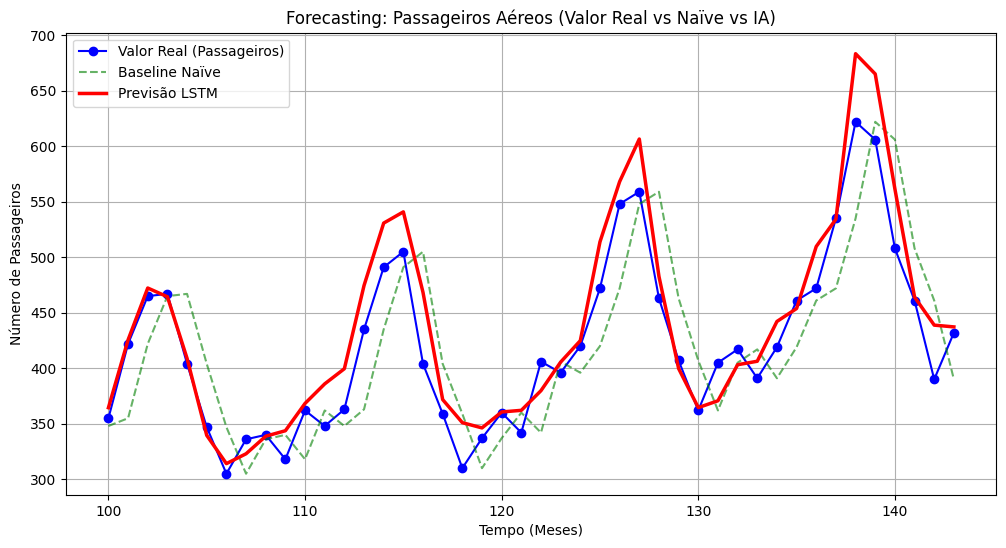

In [53]:
# ==========================================
# 7. VISUALIZAÇÃO DOS RESULTADOS
# ==========================================
plt.figure(figsize=(12, 6))
plt.plot(time_valid, x_valid, label="Valor Real (Passageiros)", color="blue", marker="o")
plt.plot(time_valid, naive_forecast, label="Baseline Naïve", color="green", alpha=0.6, linestyle="--")
plt.plot(time_valid, rnn_forecast, label="Previsão LSTM", color="red", linewidth=2.5)

plt.title("Forecasting: Passageiros Aéreos (Valor Real vs Naïve vs IA)")
plt.xlabel("Tempo (Meses)")
plt.ylabel("Número de Passageiros")
plt.legend()
plt.grid(True)
plt.show()